In [1]:
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator

In [2]:
generator = InterventionDatasetGenerator(
        function_generator="neuralnet",
        num_variables=3,
        sample_size=1000,
        batch_size=1,
        graph_type=["ER"],
        graph_degrees=[1,2,3],
        iterations_per_epoch=10,
)

/vol/bitbucket/ad6013/anaconda3/envs/meta_causal_inf/lib/python3.10/site-packages/torch/nn/init.py:511: UserWarning: Initializing zero-element tensors is a no-op
  warnings.warn("Initializing zero-element tensors is a no-op")


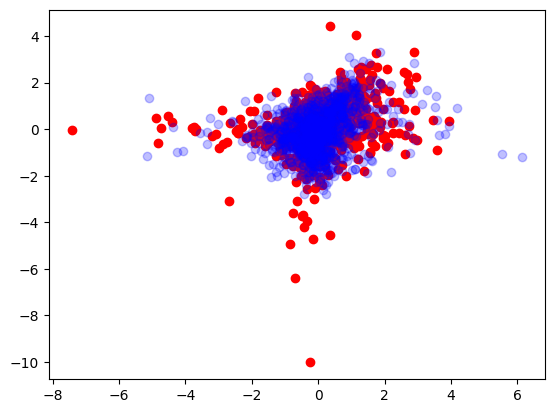

tensor([[0., 1., 1.],
        [0., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(1)
2


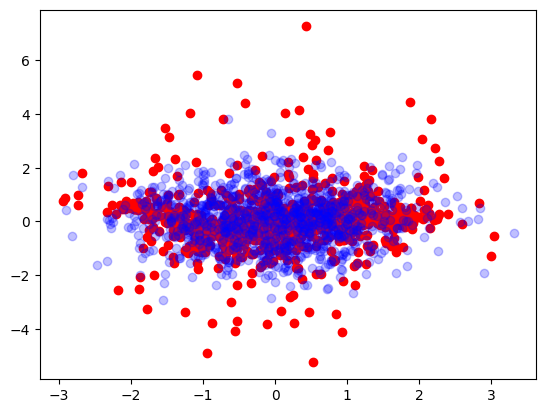

tensor([[0., 1., 1.],
        [0., 0., 0.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(2)
0


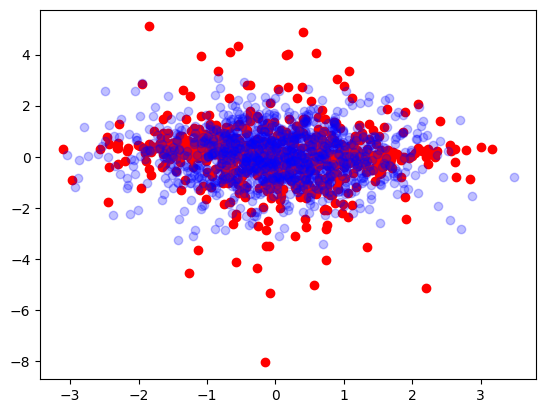

tensor([[0., 1., 0.],
        [0., 0., 0.],
        [1., 0., 0.]], dtype=torch.float64)
tensor(0)
2


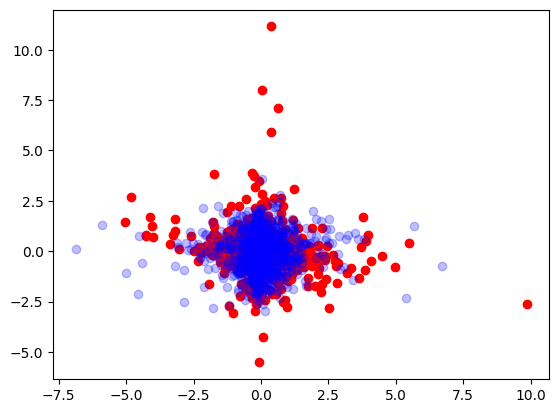

tensor([[0., 1., 0.],
        [0., 0., 0.],
        [1., 1., 0.]], dtype=torch.float64)
tensor(1)
0


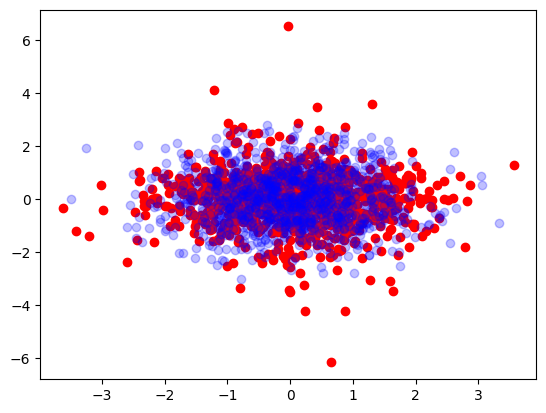

tensor([[0., 0., 0.],
        [1., 0., 0.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(0)
2


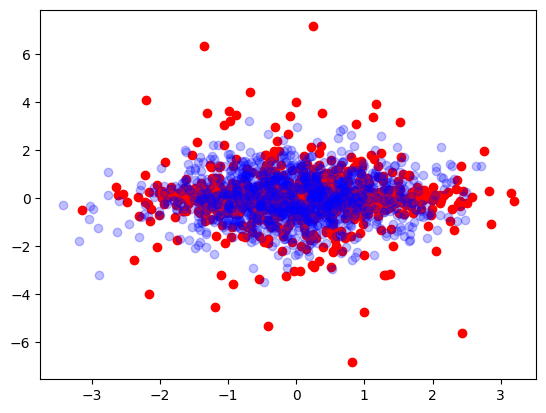

tensor([[0., 0., 0.],
        [1., 0., 0.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(0)
2


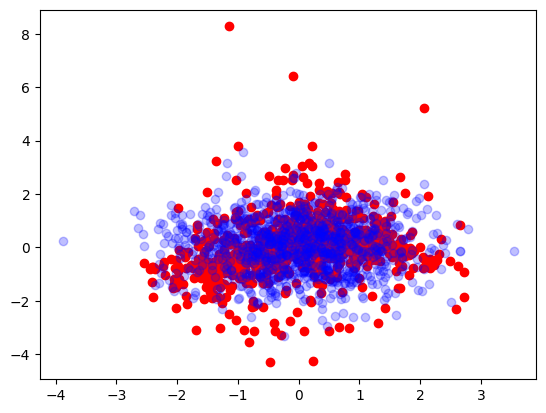

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 1., 0.]], dtype=torch.float64)
tensor(1)
2


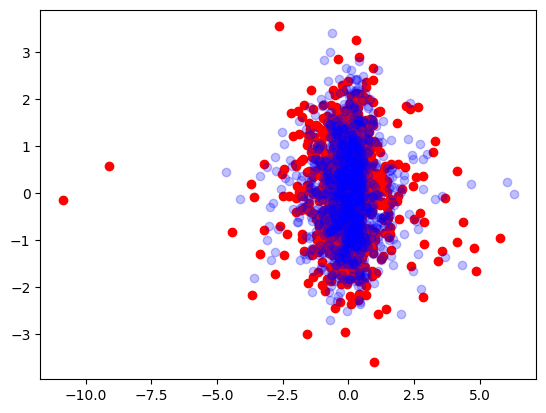

tensor([[0., 0., 1.],
        [0., 0., 0.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(1)
2


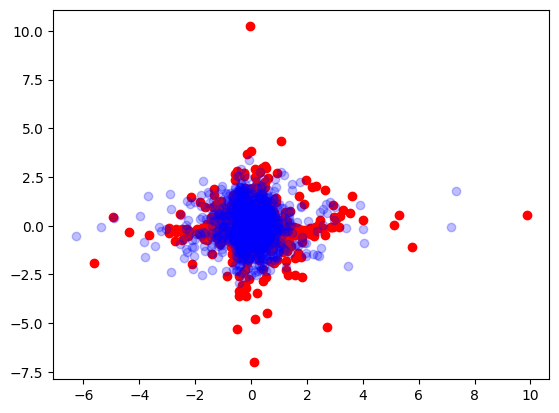

tensor([[0., 0., 0.],
        [0., 0., 1.],
        [1., 0., 0.]], dtype=torch.float64)
tensor(0)
2


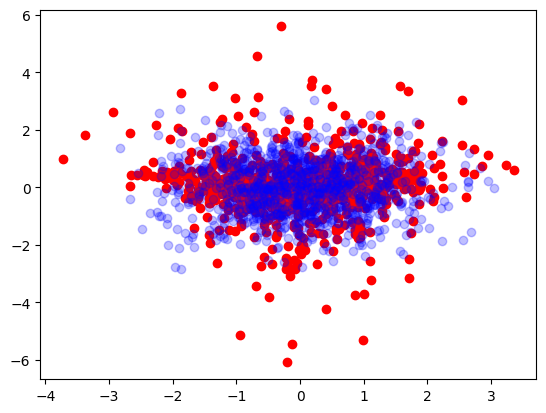

tensor([[0., 0., 1.],
        [1., 0., 1.],
        [0., 0., 0.]], dtype=torch.float64)
tensor(2)
1


<Figure size 640x480 with 0 Axes>

In [4]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import sample_outcome_index


data_loader = DataLoader(generator, batch_size=None)


for idx, batch in enumerate(data_loader):
    (
        obs_data_array,
        int_data_array,
        causal_graphs_array,
        intvn_indices,
        variable_counts,
        masks
    ) = batch

    # Sample outcome index that is not the same as the intervention index
    outcome_index = sample_outcome_index(
        variable_counts, intvn_indices
    )

    plt.scatter(obs_data_array[0][:, outcome_index[0]], obs_data_array[0][:, intvn_indices[0]], c='r')

    plt.scatter(int_data_array[0][:, outcome_index[0]], int_data_array[0][:, intvn_indices[0]], c='b', alpha=0.25)
    plt.show()
    plt.clf()
    print(causal_graphs_array[0])
    print(intvn_indices[0])
    print(outcome_index[0])

In [8]:
outcome_index

array([1])

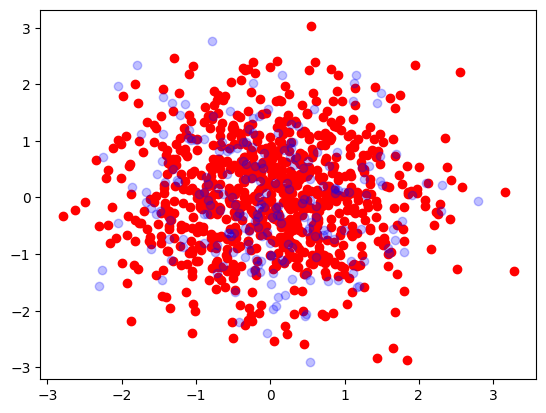

tensor(0)
tensor(1)


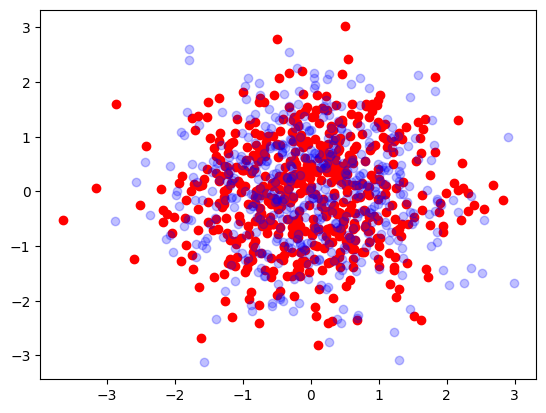

tensor(2)
tensor(0)


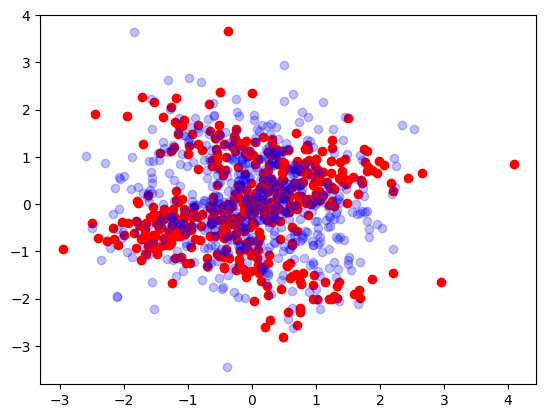

tensor(0)
tensor(1)


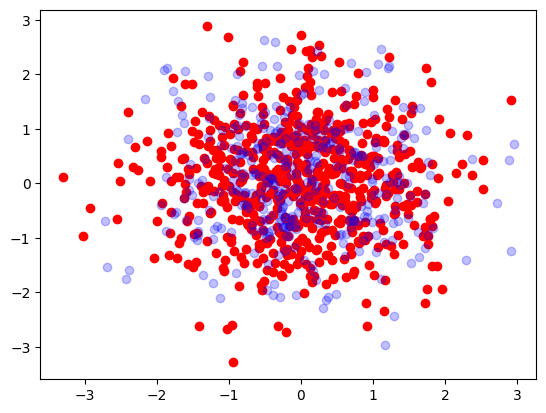

tensor(2)
tensor(0)


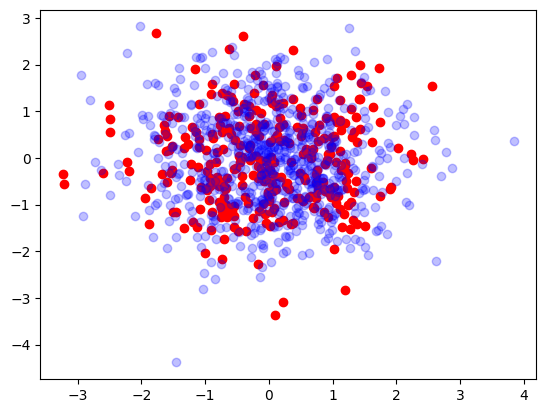

tensor(0)
tensor(2)


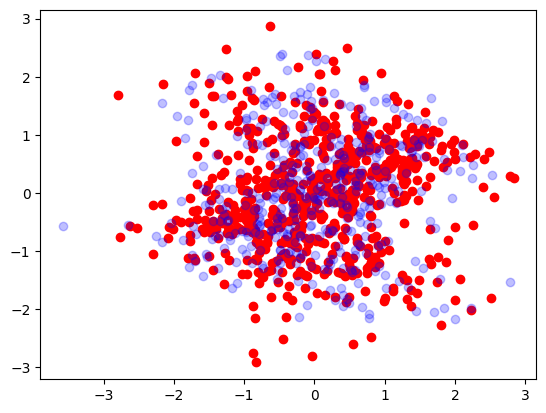

tensor(1)
tensor(0)


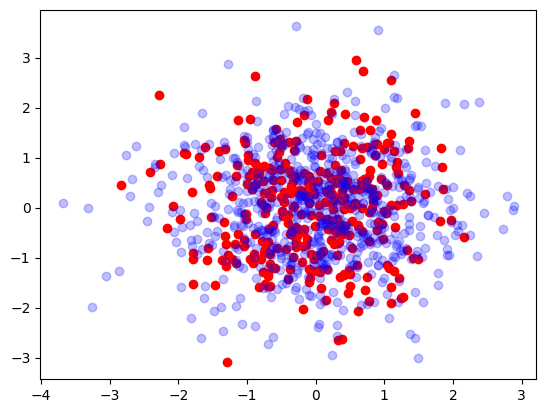

tensor(2)
tensor(1)


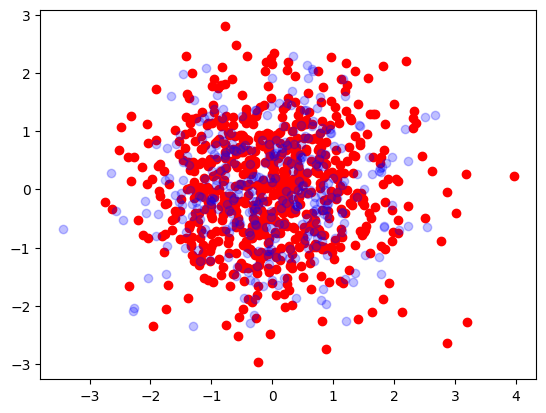

tensor(1)
tensor(0)


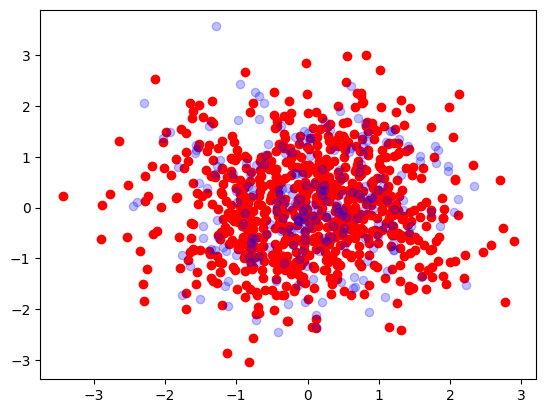

tensor(1)
tensor(2)


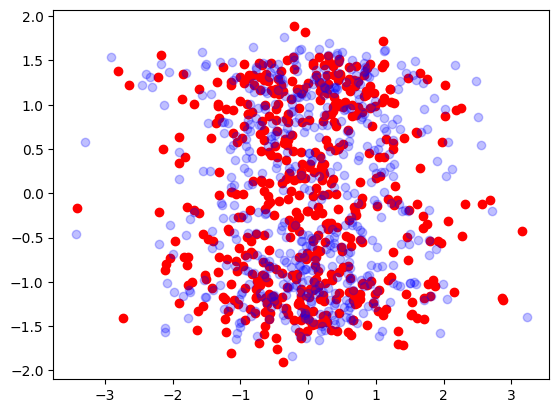

tensor(2)
tensor(1)


<Figure size 640x480 with 0 Axes>

In [14]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from CITNP.utils.datautils import transformer_inference_split_withpadding


data_loader = DataLoader(
    generator, batch_size=None,
    collate_fn=transformer_inference_split_withpadding(
        cntxt_split=[0.2, 0.8],
        sample_size=1000
    )
)


for idx, batch in enumerate(data_loader):
    (
        context, target, intvn_indices, outcome_indices, masks
    ) = batch

    plt.scatter(context[0][:,0], context[0][:,1], c='r')
    plt.scatter(target[0][:,0], target[0][:,1], c='b', alpha=0.25)
    plt.show()
    plt.clf()
    print(intvn_indices[0])
    print(outcome_indices[0])

In [10]:
context.shape

torch.Size([1, 1437, 3, 1])